# Flux versus detection significance: 400 and 128 keV cutoffs

This notebook calculates and plots the **24-month Asimov detection significance**
of an arbitrary point source at the NGC 1068 position for two cutoff power laws:

$$\frac{\mathrm{d}N}{\mathrm{d}E}=K\left(\frac{E}{200\,\mathrm{keV}}\right)^{-2.1}
\exp\!\left(-\frac{E}{E_c}\right),\qquad E_c=400\ \mathrm{or}\ 128\,\mathrm{keV}.$$

The photon index is $\Gamma=2.1$, corresponding to `SPECTRAL_INDEX = -2.1`
in the model's signed-exponent convention.

Run all cells from top to bottom using the `cosipy312` kernel. All analysis and
plotting functions are defined here; no other notebook or local helper script
is required. The inputs are the response, orientation, and preselected NGC 1068
background files listed below.

- **Flux:** integrated energy flux over 100-1,000 keV, scanned from
  $10^{-12}$ to $10^{-8}$ erg cm$^{-2}$ s$^{-1}$ at 100 logarithmically spaced points.
  Each energy-flux CSV records only integrated energy flux and TS.
- **Exposure:** the NGC 1068 60-degree pointing GTI from the three-month DC4
  orientation, repeated eight times by scaling the interval livetimes. Source
  and background expectations receive the same factor of eight.
- **Data:** floating-point source-plus-background expectations, without Poisson
  sampling. Position, photon index, and cutoff are fixed; only source amplitude
  is tested. One overall background normalization is profiled by default.
- **Zero-background cells:** excluded from both source and background in the
  likelihood, with the retained signal fraction reported for each cutoff.
- **Outputs:** one separate energy-flux CSV and PDF for each cutoff, plus a PDF
  overlaying both curves. Tables and
  plots are displayed below with detection significance on the x-axis and energy flux on the y-axis; no PNG files or JSON sidecars are written.

Additional photon-flux figures express the same results as the integrated
number of photons over 100-1,000 keV. Each photon-flux CSV contains only
`photon_flux_ph_cm2_s` and `ts`. Photon and energy fluxes are obtained by
integrating the same fixed CPL shape; the TS values are unchanged.


In [1]:
from pathlib import Path

import astropy.units as u
from astropy.coordinates import SkyCoord
from astromodels import Cutoff_powerlaw, Model, PointSource
from histpy import Histogram
from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.integrate import quad

from cosipy import SpacecraftHistory, SourceInjector
from cosipy.event_selection import GoodTimeInterval

%matplotlib inline


No event loop hook running.


13:36:18 WARNING   The naima package is not available. Models    functions.py:43
                  that depend on it will not be available                       
         WARNING   The GSL library or the pygsl wrapper cannot   functions.py:65
                  be loaded. Models that depend on it will not                  
                  be available.                                                 
13:36:19 WARNING   The ebltable package is not available.       absorption.py:33
                  Models that depend on it will not be                          
                  available                                                     
13:36:20 INFO      Starting 3ML!                                  __init__.py:44
         WARNING   WARNINGs here are NOT errors                   __init__.py:45
         WARNING   but are inform you about optional packages     __init__.py:46
                  that can be installed                                         
         WARNING    to disab

## 1. Inputs and shared settings

The input background already has the same NGC 1068 60-degree pointing cut as the
orientation selection below. Its three-month counts are scaled by eight, rather
than selecting a new background for each cutoff. Change `EXPOSURE_MONTHS` to
rerun both cases at another exposure using the same pointing distribution.
Each output filename states its cutoff and exposure; the two cases use separate
folders under `outputs` beside this notebook.

**Flux integration band:** 100-1,000 keV for both energy and photon flux.
The detection likelihood still uses the original 100-10,000 keV measured-energy
range. The CPL is folded through the full response without truncation at
1,000 keV. The grid and reference flux are normalized to the reporting band;
changing this band therefore changes the source amplitude at a fixed grid
value. Output filenames include the flux-band limits.


In [2]:
NOTEBOOK_DIR = Path('/Users/parshadkp/Software/cosipy/docs/tutorials/source_injector')
DATA_DIR = Path(
    '/Users/parshadkp/Library/CloudStorage/OneDrive-ClemsonUniversity/'
    'COSI/Radio_Quiet_AGN/DC4_Files'
)
RESPONSE_PATH = DATA_DIR / (
    'ResponseContinuum.o3.e100_10000.b10log.s10396905069491.m2284.'
    'filtered.nonsparse.binnedimaging.imagingresponse.h5'
)
ORIENTATION_PATH = DATA_DIR / 'DC4_final_530km_3_month_with_slew_15sbins_GalacticEarth_SAA.fits'
BACKGROUND_PATH = DATA_DIR / 'Background' / (
    'Total_DC4_BG_3months_binned_data_filtered_with_SAAcut_withSAAbck_'
    'NGC1068_60deg_fov_cut.hdf5'
)
OUTPUT_ROOT = NOTEBOOK_DIR / 'outputs'
BASE_EXPOSURE_MONTHS = 3
EXPOSURE_MONTHS = 24
EXPOSURE_MULTIPLIER = EXPOSURE_MONTHS / BASE_EXPOSURE_MONTHS

LONGITUDE_DEG, LATITUDE_DEG = 172.104, -51.934
FOV_CUT = 60.0 * u.deg
SPECTRAL_INDEX = -2.1
SPECTRAL_INDEX_TAG = f'{SPECTRAL_INDEX:g}'.replace('-', 'm').replace('.', 'p')
PIVOT_KEV = 200.0
FLUX_BAND_KEV = (100.0, 1000.0)
FLUX_BAND_TAG = f'band{FLUX_BAND_KEV[0]:g}_{FLUX_BAND_KEV[1]:g}keV' 
N_FLUX_POINTS = 100
FLUX_POINTS = np.geomspace(1e-12, 1e-8, N_FLUX_POINTS) * u.erg / (u.cm**2 * u.s)
REFERENCE_FLUX = 1e-10 * u.erg / (u.cm**2 * u.s)
PROFILE_BACKGROUND = True  # Profile one nonnegative background scale in the null.

if not np.isfinite(EXPOSURE_MULTIPLIER) or EXPOSURE_MULTIPLIER <= 0:
    raise ValueError('The exposure multiplier must be positive and finite.')
for path in (RESPONSE_PATH, ORIENTATION_PATH, BACKGROUND_PATH):
    if not path.is_file():
        raise FileNotFoundError(path)
if not 0 < FLUX_BAND_KEV[0] < FLUX_BAND_KEV[1]:
    raise ValueError('The integrated-flux energy band must be positive and increasing.')
flux_values = FLUX_POINTS.to_value(u.erg / (u.cm**2 * u.s))
if flux_values.ndim != 1 or len(flux_values) < 2 or not np.all(np.isfinite(flux_values)):
    raise ValueError('Supply at least two finite flux points.')
if np.any(flux_values <= 0) or np.any(np.diff(flux_values) <= 0):
    raise ValueError('Flux points must be positive and strictly increasing.')
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)


## 2. Select the NGC 1068 GTI and scale the exposure

The pointing GTI uses `earth_occ=False`, matching the reference NGC 1068
injection setup. Earth occultation is included later when folding the source
response (`earth_occ=True`). Multiplying the selected interval livetimes by
eight preserves the sampled pointings and occultation geometry while increasing
the response-integrated exposure. This is a 24-month extrapolation of the
three-month pointing history.

The source response is folded through this scaled orientation, so its expected
counts already include the exposure multiplier. The source flux itself remains
an intrinsic flux and is not multiplied by eight.


In [3]:
source_coord = SkyCoord(l=LONGITUDE_DEG, b=LATITUDE_DEG, unit='deg', frame='galactic')
full_orientation = SpacecraftHistory.open(ORIENTATION_PATH)
source_gti = GoodTimeInterval.from_pointing_cut(
    source_coord, full_orientation, FOV_CUT, earth_occ=False,
)
orientation_gti_3m = full_orientation.apply_gti(source_gti)
base_livetime_s = float(orientation_gti_3m.cumulative_livetime().to_value(u.s))
orientation_gti = SpacecraftHistory(
    orientation_gti_3m.obstime,
    orientation_gti_3m.attitude,
    orientation_gti_3m.location,
    livetime=orientation_gti_3m.livetime * EXPOSURE_MULTIPLIER,
)
orientation_gti.cache_earth_occ = orientation_gti_3m.cache_earth_occ
livetime_s = float(orientation_gti.cumulative_livetime().to_value(u.s))
np.testing.assert_allclose(livetime_s, base_livetime_s * EXPOSURE_MULTIPLIER)
if len(source_gti) == 0 or livetime_s <= 0:
    raise ValueError('The pointing cut selected no usable exposure.')
print(f'GTI intervals: {len(source_gti):,}')
print(f'Selected three-month livetime: {base_livetime_s:,.1f} s')
print(f'Exposure multiplier: {EXPOSURE_MULTIPLIER:g}')
print(f'Scaled {EXPOSURE_MONTHS:g}-month livetime: {livetime_s:,.1f} s')

# The same exposure-scaled background is used for both cutoff cases.
background = (
    Histogram.open(BACKGROUND_PATH).project('Em', 'Phi', 'PsiChi')
    * EXPOSURE_MULTIPLIER
)


GTI intervals: 1,300
Selected three-month livetime: 2,546,115.0 s
Exposure multiplier: 8
Scaled 24-month livetime: 20,368,920.0 s


## 3. Define the binned Asimov detection statistic

Keep the full measured-energy/Compton-data-space binning (`Em`, `Phi`, `PsiChi`).
A single support mask, $b_i>0$, selects cells for both source and background.
Zero simulated background events do not establish a truly zero physical
background, so these cells are excluded rather than assigning a pseudocount.
The full source expectation is retained separately for the count diagnostics.

For each trial flux the Asimov data are $n_i=s_i+b_i$. The generating model is
the source-plus-background likelihood maximum. The exact zero-source null
fits one nonnegative background scale,
$\hat\beta_0=\sum_i n_i/\sum_i b_i$, giving

$$\mathrm{TS}_A=2\sum_i\left[n_i\ln\frac{n_i}{\hat\beta_0b_i}
+\hat\beta_0b_i-n_i\right],\qquad Z_A=\sqrt{\mathrm{TS}_A}.$$

$Z_A$ is the nominal one-sided local significance for a fixed position and
spectral shape with one nonnegative source amplitude; no search trials
correction is applied. Set `PROFILE_BACKGROUND=False` to hold the background
scale at one. The implementation evaluates an equivalent expression with a
small-ratio series for numerical accuracy at faint fluxes.


In [4]:
def histogram_values(histogram):
    values = histogram.contents
    if hasattr(values, 'compute'):
        values = values.compute()
    if hasattr(values, 'todense'):
        values = values.todense()
    if hasattr(values, 'value'):
        values = values.value
    return np.asarray(values, dtype=float)

def poisson_deviance_kernel(ratio):
    # h(r) = (1+r)*log(1+r)-r, with a series near zero.
    ratio = np.asarray(ratio, dtype=float)
    small = ratio < 1e-4
    result = np.empty_like(ratio)
    r = ratio[small]
    result[small] = r*r*(0.5 + r*(-1/6 + r*(1/12 + r*(-1/20 + r/30))))
    r = ratio[~small]
    result[~small] = (1+r)*np.log1p(r)-r
    return result


def asimov_detection_ts(signal, background_counts, *, profile_background=True):
    signal = np.asarray(signal, dtype=float).ravel()
    background_counts = np.asarray(background_counts, dtype=float).ravel()
    if signal.shape != background_counts.shape or signal.size == 0:
        raise ValueError('Signal and background must have matching nonempty shapes.')
    if (not np.all(np.isfinite(signal)) or np.any(signal < 0)
            or not np.all(np.isfinite(background_counts)) or np.any(background_counts <= 0)):
        raise ValueError('Require finite signal >= 0 and background > 0 in every retained cell.')
    signal_total = float(signal.sum())
    background_total = float(background_counts.sum())
    fixed_ts = float(2 * np.sum(
        background_counts * poisson_deviance_kernel(signal / background_counts)
    ))
    null_scale = 1.0
    null_gain = 0.0
    if profile_background:
        total_ratio = signal_total / background_total
        null_scale += total_ratio
        null_gain = float(2 * background_total * poisson_deviance_kernel(total_ratio))
    ts = fixed_ts - null_gain
    if ts < -1e-9 * max(1.0, fixed_ts):
        raise ArithmeticError('Unexpected negative likelihood-ratio TS.')
    return max(0.0, ts), null_scale


## 4. Calculate one cutoff case and save its CSV

For each cutoff, normalize the reference spectrum to an integrated energy flux
of $10^{-10}$ erg cm$^{-2}$ s$^{-1}$ using $\int E\,\mathrm{d}N/\mathrm{d}E\,\mathrm{d}E$
and the keV-to-erg conversion. Fold that reference spectrum once through the
24-month response. All other flux points follow by linear scaling of its
expected detector counts.

Each CSV contains only `energy_flux_erg_cm2_s` and `ts`. The other results
remain available in the notebook for plotting and diagnostics. The common
input paths and statistical assumptions are documented in this notebook. Each returned case dictionary also keeps the
source template and mask for a future Poisson-realization study.


In [5]:
def calculate_cutoff_case(cutoff_keV):
    """Fold one fixed CPL shape, evaluate its flux scan, and write one CSV."""
    cutoff_keV = float(cutoff_keV)
    if not np.isfinite(cutoff_keV) or cutoff_keV <= 0:
        raise ValueError('Cutoff energy must be positive and finite.')
    print(f'Cutoff: {cutoff_keV:g} keV; exposure: {EXPOSURE_MONTHS:g} months')
    output_dir = OUTPUT_ROOT / f'NGC1068_CPL{cutoff_keV:g}_Asimov'
    output_dir.mkdir(parents=True, exist_ok=True)
    output_stem = (
        f'NGC1068_GTI_CPL_index_{SPECTRAL_INDEX_TAG}_Ec{cutoff_keV:g}_{EXPOSURE_MONTHS:g}months_'
        f'{FLUX_BAND_TAG}_Asimov_flux_significance'
    )
    energy_min, energy_max = map(float, FLUX_BAND_KEV)

    def unit_k_shape(energy_keV):
        return (energy_keV / PIVOT_KEV)**SPECTRAL_INDEX * np.exp(-energy_keV / cutoff_keV)

    energy_flux_per_k = quad(
        lambda energy: energy * unit_k_shape(energy), energy_min, energy_max,
        epsabs=0.0, epsrel=1e-10,
    )[0] * u.keV.to(u.erg)
    photon_flux_per_k = quad(
        unit_k_shape, energy_min, energy_max, epsabs=0.0, epsrel=1e-10,
    )[0]
    reference_flux_value = REFERENCE_FLUX.to_value(u.erg / (u.cm**2 * u.s))
    if not np.isfinite(reference_flux_value) or reference_flux_value <= 0:
        raise ValueError('REFERENCE_FLUX must be positive and finite.')
    reference_k = reference_flux_value / energy_flux_per_k

    spectrum = Cutoff_powerlaw()
    spectrum.K.value = reference_k
    spectrum.K.unit = u.keV**-1 * u.cm**-2 * u.s**-1
    spectrum.piv.value = PIVOT_KEV
    spectrum.piv.unit = u.keV
    spectrum.index.value = SPECTRAL_INDEX
    spectrum.xc.value = cutoff_keV
    spectrum.xc.unit = u.keV
    for parameter in (spectrum.K, spectrum.piv, spectrum.index, spectrum.xc):
        parameter.fix = True
    source = PointSource(
        'arbitrary_CPL', l=LONGITUDE_DEG, b=LATITUDE_DEG, spectral_shape=spectrum,
    )
    injection_model = Model(source)
    injector = SourceInjector(response_path=RESPONSE_PATH)
    # Scaling the orientation livetimes scales the folded source expectation.
    source_reference = injector.inject_model(
        model=injection_model, orientation=orientation_gti,
        fluctuate=False, earth_occ=True, make_spectrum_plot=False,
    ).project('Em', 'Phi', 'PsiChi')
    print(f'Reference K at {PIVOT_KEV:g} keV: {reference_k:.6g} ph cm^-2 s^-1 keV^-1')

    if not np.array_equal(source_reference.axes.labels, background.axes.labels):
        raise ValueError('Source and background axis labels differ.')
    for source_axis, background_axis in zip(source_reference.axes, background.axes):
        if source_axis.edges.shape != background_axis.edges.shape or not np.allclose(
            source_axis.edges, background_axis.edges, rtol=1e-10, atol=0,
        ):
            raise ValueError(f'Source/background bin edges differ on {source_axis.label}.')
        for attribute in ('nside', 'scheme'):
            if getattr(source_axis, attribute, None) != getattr(background_axis, attribute, None):
                raise ValueError(f'Source/background {attribute} differs on {source_axis.label}.')
        source_frame = getattr(source_axis, 'coordsys', None)
        background_frame = getattr(background_axis, 'coordsys', None)
        if hasattr(source_frame, 'is_equivalent_frame'):
            frames_match = source_frame.is_equivalent_frame(background_frame)
        else:
            frames_match = source_frame == background_frame
        if not frames_match:
            raise ValueError(f'Source/background coordinate frames differ on {source_axis.label}.')

    source_all = histogram_values(source_reference).ravel()
    background_all = histogram_values(background).ravel()
    if source_all.shape != background_all.shape:
        raise ValueError('Source and background detector shapes differ.')
    for values in (source_all, background_all):
        if not np.all(np.isfinite(values)) or np.any(values < 0):
            raise ValueError('Expected counts must be finite and nonnegative.')
    support_mask = background_all > 0
    source_template = source_all[support_mask]
    background_template = background_all[support_mask]
    if source_template.sum() <= 0 or background_template.sum() <= 0:
        raise ValueError('No supported source or background counts.')
    retained_source_fraction = float(source_template.sum() / source_all.sum())
    print(f'Measured-energy range: {background.axes["Em"].edges[[0, -1]]}')
    print(f'Positive-background cells: {support_mask.sum():,} / {support_mask.size:,}')
    print(f'Retained reference source counts: {source_template.sum():,.3f}')
    print(f'Retained source fraction: {retained_source_fraction:.4%}')
    print(f'Background counts in the likelihood: {background_template.sum():,.0f}')

    rows = []
    for flux in flux_values:
        scale = float(flux / reference_flux_value)
        signal = scale * source_template
        ts, null_scale = asimov_detection_ts(
            signal, background_template, profile_background=PROFILE_BACKGROUND,
        )
        rows.append({
            'energy_flux_erg_cm2_s': float(flux),
            'photon_flux_ph_cm2_s': float(flux / energy_flux_per_k * photon_flux_per_k),
            'significance_sigma': float(np.sqrt(ts)),
            'ts': ts,
            'K_ph_cm2_s_keV': float(reference_k * scale),
            'cutoff_keV': cutoff_keV,
            'spectral_index': SPECTRAL_INDEX,
            'pivot_keV': PIVOT_KEV,
            'retained_source_fraction': retained_source_fraction,
            'source_counts_likelihood': float(signal.sum()),
            'source_counts_all_cells': float(scale * source_all.sum()),
            'background_counts_likelihood': float(background_template.sum()),
            'null_background_scale': null_scale,
            'livetime_s': livetime_s,
            'exposure_months': EXPOSURE_MONTHS,
            'exposure_multiplier': EXPOSURE_MULTIPLIER,
            'flux_band_min_keV': energy_min,
            'flux_band_max_keV': energy_max,
            'profile_background': PROFILE_BACKGROUND,
        })
    results = pd.DataFrame(rows)
    csv_path = output_dir / f'{output_stem}.csv'
    results[['energy_flux_erg_cm2_s', 'ts']].to_csv(
        csv_path, index=False, float_format='%.12g',
    )
    display(results[['energy_flux_erg_cm2_s', 'photon_flux_ph_cm2_s', 'significance_sigma', 'ts']])
    print('Saved:', csv_path)
    return {
        'cutoff_keV': cutoff_keV, 'results': results, 'csv_path': csv_path,
        'pdf_path': output_dir / f'{output_stem}.pdf',
        'source_reference': source_reference, 'source_template': source_template,
        'background_template': background_template, 'source_all': source_all,
        'support_mask': support_mask, 'retained_source_fraction': retained_source_fraction,
        'reference_k': reference_k,
    }


## 5. Define the common plot style

All figures use the `Fluctuate_True` spectral-fitting style: Times New Roman,
25-point regular-weight text, a 12 x 9 inch figure, inward ticks on all sides, 1.5-point
spines, with orange for 400 keV and blue for 128 keV. The cutoff is identified
in the curve legend; the annotation gives NGC 1068 and the exposure. Detection significance is on the x-axis and energy flux on the y-axis. Both
axes use log scales, with vertical reference lines at 3 and 5 sigma. Each figure is displayed inline and exported as a PDF.

The plot also reports integrated energy fluxes in 100-250 and 250-400 keV
at each curve's 3-sigma threshold (TS=9, or median TS=9 for the Poisson curve).
The threshold is interpolated between calculated flux points in log flux and
log TS. Band values are calculated by integrating the same CPL shape over
each requested energy range. Colored values correspond to the matching curve
in the legend; all values are in erg cm^-2 s^-1. The two-column CSV format is
unchanged.


In [6]:

def band_fluxes_at_three_sigma(case):
    """Interpolate TS=9, then integrate that spectrum over the two bands."""
    frame = case['results'].sort_values('energy_flux_erg_cm2_s')
    energy_flux = frame['energy_flux_erg_cm2_s'].to_numpy(float)
    ts = frame['ts'].to_numpy(float)
    crossings = np.flatnonzero((ts[:-1] < 9.0) & (ts[1:] >= 9.0))
    if crossings.size == 0:
        raise ValueError('The calculated curve does not bracket the 3-sigma threshold.')
    lower = int(crossings[0])
    upper = lower + 1
    if ts[lower] > 0:
        weight = (np.log(9.0) - np.log(ts[lower])) / (np.log(ts[upper]) - np.log(ts[lower]))
    else:
        weight = (9.0 - ts[lower]) / (ts[upper] - ts[lower])
    threshold_flux = float(np.exp(
        np.log(energy_flux[lower]) + weight * np.log(energy_flux[upper] / energy_flux[lower])
    ))
    cutoff_keV = float(case['cutoff_keV'])

    def energy_weight(energy_keV):
        return energy_keV * (energy_keV / PIVOT_KEV)**SPECTRAL_INDEX * np.exp(-energy_keV / cutoff_keV)

    full_integral = quad(energy_weight, *FLUX_BAND_KEV, epsabs=0.0, epsrel=1e-10)[0]
    band_100_250 = threshold_flux * quad(
        energy_weight, 100.0, 250.0, epsabs=0.0, epsrel=1e-10,
    )[0] / full_integral
    band_250_400 = threshold_flux * quad(
        energy_weight, 250.0, 400.0, epsabs=0.0, epsrel=1e-10,
    )[0] / full_integral
    def photon_weight(energy_keV):
        return (energy_keV / PIVOT_KEV)**SPECTRAL_INDEX * np.exp(-energy_keV / cutoff_keV)

    threshold_k = threshold_flux / (full_integral * u.keV.to(u.erg))
    return {
        'threshold_photon_flux_ph_cm2_s': threshold_k * quad(
            photon_weight, *FLUX_BAND_KEV, epsabs=0.0, epsrel=1e-10,
        )[0],
        'flux_100_250_ph_cm2_s': threshold_k * quad(
            photon_weight, 100.0, 250.0, epsabs=0.0, epsrel=1e-10,
        )[0],
        'flux_250_400_ph_cm2_s': threshold_k * quad(
            photon_weight, 250.0, 400.0, epsabs=0.0, epsrel=1e-10,
        )[0],
        'threshold_flux_erg_cm2_s': threshold_flux,
        'flux_100_250_erg_cm2_s': float(band_100_250),
        'flux_250_400_erg_cm2_s': float(band_250_400),
    }


def scientific_flux_label(value):
    exponent = int(np.floor(np.log10(value)))
    coefficient = value / 10.0**exponent
    return rf'${coefficient:.2f}\times10^{{{exponent}}}$'


def plot_cutoff_cases(cases, pdf_path, *, flux_kind="energy"):
    """Display energy- or photon-flux curves with a shared style."""
    if flux_kind not in ('energy', 'photon'):
        raise ValueError('flux_kind must be energy or photon.')
    flux_column = 'photon_flux_ph_cm2_s' if flux_kind == 'photon' else 'energy_flux_erg_cm2_s'
    annotation_unit = 'ph_cm2_s' if flux_kind == 'photon' else 'erg_cm2_s'
    flux_label = 'Photon flux' if flux_kind == 'photon' else 'Energy flux'
    flux_units = r'ph cm$^{-2}$ s$^{-1}$' if flux_kind == 'photon' else r'erg cm$^{-2}$ s$^{-1}$' 
    energy_min, energy_max = map(float, FLUX_BAND_KEV)
    FONT_SIZE = 25
    FIGURE_SIZE = (12, 9)
    plot_style = {
        'agg.path.chunksize': 10000,
        'font.size': FONT_SIZE, 'font.family': 'Times New Roman', 'font.weight': 'normal',
        'axes.linewidth': 1.5, 'axes.labelsize': FONT_SIZE, 'axes.labelweight': 'normal',
        'axes.titleweight': 'normal', 'xtick.labelsize': FONT_SIZE,
        'ytick.labelsize': FONT_SIZE, 'legend.fontsize': FONT_SIZE,
    }
    with plt.rc_context(plot_style):
        fig, ax = plt.subplots(figsize=FIGURE_SIZE, constrained_layout=True)
        colors = {400.0: '#D55E00', 128.0: '#0072B2'}
        for case in cases:
            results = case['results']
            ax.plot(
                results['significance_sigma'], results[flux_column],
                color=colors.get(float(case['cutoff_keV']), '0.25'),
                lw=2,
                markerfacecolor='white', markeredgewidth=1.6,
                label=rf"$E_{{\rm c,th}}$ = {case['cutoff_keV']:g} keV",
            )
        for threshold, linestyle in ((3, '--'), (5, ':')):
            ax.axvline(threshold, color='0.4', lw=1.5, ls=linestyle, label=fr'{threshold}$\sigma$')
        for coordinate in ('x', 'y'):
            ax.tick_params(
                axis=coordinate, which='major', size=12, width=1.5,
                direction='in', pad=8, labelsize=FONT_SIZE,
            )
            ax.tick_params(axis=coordinate, which='minor', size=6, width=1.5, direction='in')
        ax.tick_params(axis='x', which='both', top=True, bottom=True)
        ax.tick_params(axis='y', which='both', left=True, right=True)
        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_linewidth(1.5)
        ax.set_xscale('log')
        ax.minorticks_on()
        ax.set_xlim(
            min(case['results']['significance_sigma'].min() for case in cases),
            max(case['results']['significance_sigma'].max() for case in cases),
        )
        ax.set_ylim(
            min(case['results'][flux_column].min() for case in cases),
            max(case['results'][flux_column].max() for case in cases),
        )
        ax.set_yscale('log')
        ylabel = f'{flux_label}, {energy_min:g}-{energy_max:g} keV\n({flux_units})'
        ax.set_ylabel(ylabel)
        ax.set_xlabel(r'Detection significance ($\sigma$)')
        ax.text(
            0.04, 0.96,
            f'NGC 1068\n{EXPOSURE_MONTHS:g} months',
            transform=ax.transAxes, ha='left', va='top', fontsize=FONT_SIZE,
            bbox=dict(facecolor='white', edgecolor='none', pad=4),
        )

        ax.text(
            0.04, 0.80, r'3$\sigma$ ' + flux_label.lower() + f' ({flux_units})',
            transform=ax.transAxes, ha='left', va='top', fontsize=FONT_SIZE-5,
            bbox=dict(facecolor='white', edgecolor='none', pad=4),
        )
        for index, case in enumerate(cases):
            band_flux = band_fluxes_at_three_sigma(case)
            case['band_fluxes_3sigma'] = band_flux
            annotation = (
                '100-250 keV: ' + scientific_flux_label(band_flux[f'flux_100_250_{annotation_unit}'])
                + '\n250-400 keV: ' + scientific_flux_label(band_flux[f'flux_250_400_{annotation_unit}'])
            )
            ax.text(
                0.04, 0.74 - 0.12*index, annotation,
                color=colors.get(float(case['cutoff_keV']), '0.25'),
                transform=ax.transAxes, ha='left', va='top', fontsize=FONT_SIZE-5,
                bbox=dict(facecolor='white', edgecolor='none', pad=4),
            )

        ax.legend(loc='lower right', frameon=False)
        plot_path = pdf_path
        fig.savefig(plot_path, format='pdf', bbox_inches='tight')
        plt.show()
    print('Saved:', plot_path)
    return fig, ax


def plot_cutoff_case(case):
    """Display and save one cutoff case with its cutoff in the legend."""
    return plot_cutoff_cases([case], case['pdf_path'])


## 6. Cutoff energy: 400 keV

Calculate all 100 flux points, display the count diagnostics and results table,
and save the 400-keV CSV and PDF. This cell uses the shared 24-month GTI,
background, flux grid, and likelihood settings defined above.


Cutoff: 400 keV; exposure: 24 months
Reference K at 200 keV: 1.54893e-06 ph cm^-2 s^-1 keV^-1
Measured-energy range: [  100. 10000.] keV
Positive-background cells: 202,155 / 230,400
Retained reference source counts: 222,256.480
Retained source fraction: 99.9991%
Background counts in the likelihood: 507,151,368
Saved: /Users/parshadkp/Software/cosipy/docs/tutorials/source_injector/outputs/NGC1068_CPL400_Asimov/NGC1068_GTI_CPL_index_m2p1_Ec400_24months_band100_1000keV_Asimov_flux_significance.csv
Saved: /Users/parshadkp/Software/cosipy/docs/tutorials/source_injector/outputs/NGC1068_CPL400_Asimov/NGC1068_GTI_CPL_index_m2p1_Ec400_24months_band100_1000keV_Asimov_flux_significance.pdf


    energy_flux_erg_cm2_s  photon_flux_ph_cm2_s  significance_sigma  \
0            1.000000e-12              0.000003            0.106445   
1            1.097499e-12              0.000004            0.116823   
2            1.204504e-12              0.000004            0.128213   
3            1.321941e-12              0.000004            0.140714   
4            1.450829e-12              0.000005            0.154433   
..                    ...                   ...                 ...   
95           6.892612e-09              0.022356          716.690625   
96           7.564633e-09              0.024536          784.840891   
97           8.302176e-09              0.026928          859.301875   
98           9.111628e-09              0.029554          940.626260   
99           1.000000e-08              0.032435         1029.409434   

              ts  
0   1.133052e-02  
1   1.364764e-02  
2   1.643862e-02  
3   1.980035e-02  
4   2.384957e-02  
..           ...  
95  5.136455e+

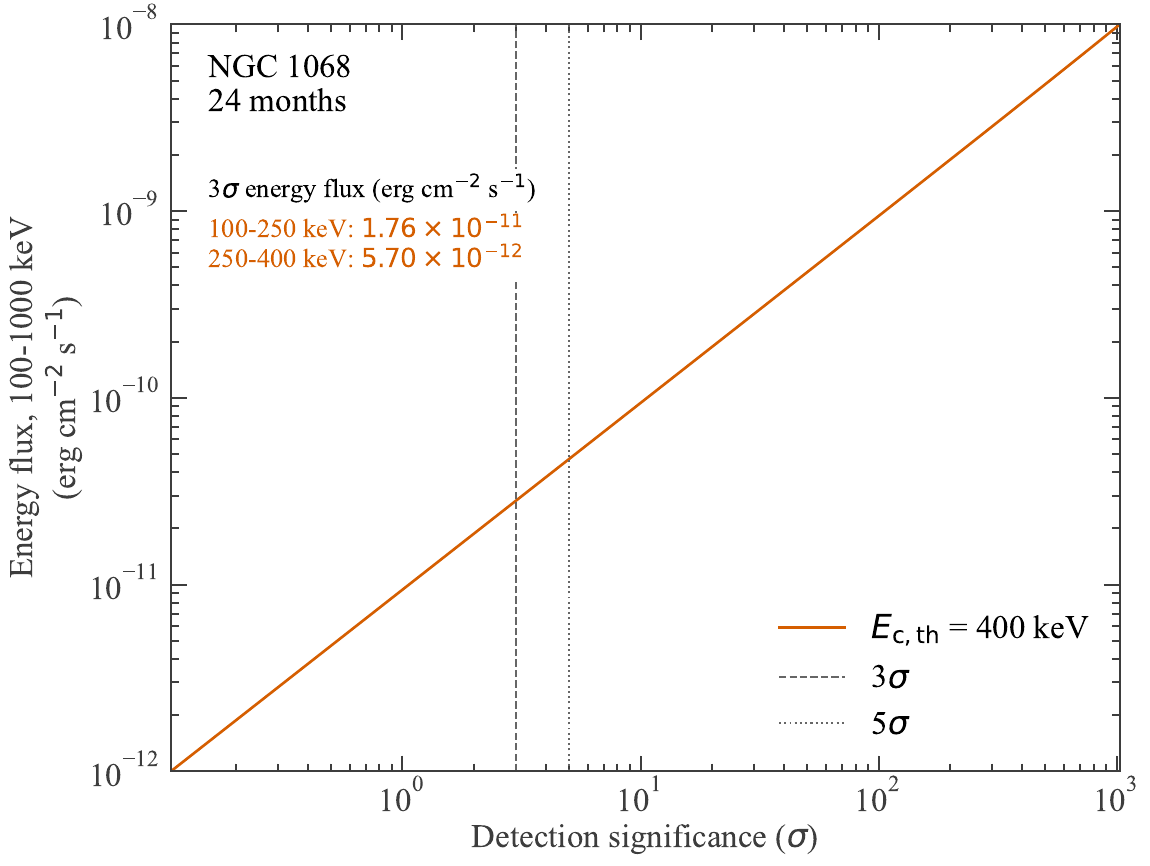

In [7]:
case_400 = calculate_cutoff_case(400.0)
fig_400, ax_400 = plot_cutoff_case(case_400)


## 7. Cutoff energy: 128 keV

Repeat the same calculation with a 128-keV cutoff. Its normalization is
recalculated for the same integrated flux band. Its CSV and PDF have distinct
names and are saved in the 128-keV output folder.


Cutoff: 128 keV; exposure: 24 months
Reference K at 200 keV: 4.7647e-06 ph cm^-2 s^-1 keV^-1
Measured-energy range: [  100. 10000.] keV
Positive-background cells: 202,155 / 230,400
Retained reference source counts: 208,304.342
Retained source fraction: 99.9991%
Background counts in the likelihood: 507,151,368
Saved: /Users/parshadkp/Software/cosipy/docs/tutorials/source_injector/outputs/NGC1068_CPL128_Asimov/NGC1068_GTI_CPL_index_m2p1_Ec128_24months_band100_1000keV_Asimov_flux_significance.csv
Saved: /Users/parshadkp/Software/cosipy/docs/tutorials/source_injector/outputs/NGC1068_CPL128_Asimov/NGC1068_GTI_CPL_index_m2p1_Ec128_24months_band100_1000keV_Asimov_flux_significance.pdf


    energy_flux_erg_cm2_s  photon_flux_ph_cm2_s  significance_sigma  \
0            1.000000e-12              0.000004            0.125288   
1            1.097499e-12              0.000004            0.137503   
2            1.204504e-12              0.000005            0.150910   
3            1.321941e-12              0.000005            0.165623   
4            1.450829e-12              0.000006            0.181771   
..                    ...                   ...                 ...   
95           6.892612e-09              0.028042          841.944139   
96           7.564633e-09              0.030776          921.851833   
97           8.302176e-09              0.033776         1009.131669   
98           9.111628e-09              0.037069         1104.424749   
99           1.000000e-08              0.040684         1208.421044   

              ts  
0   1.569708e-02  
1   1.890717e-02  
2   2.277374e-02  
3   2.743103e-02  
4   3.304073e-02  
..           ...  
95  7.088699e+

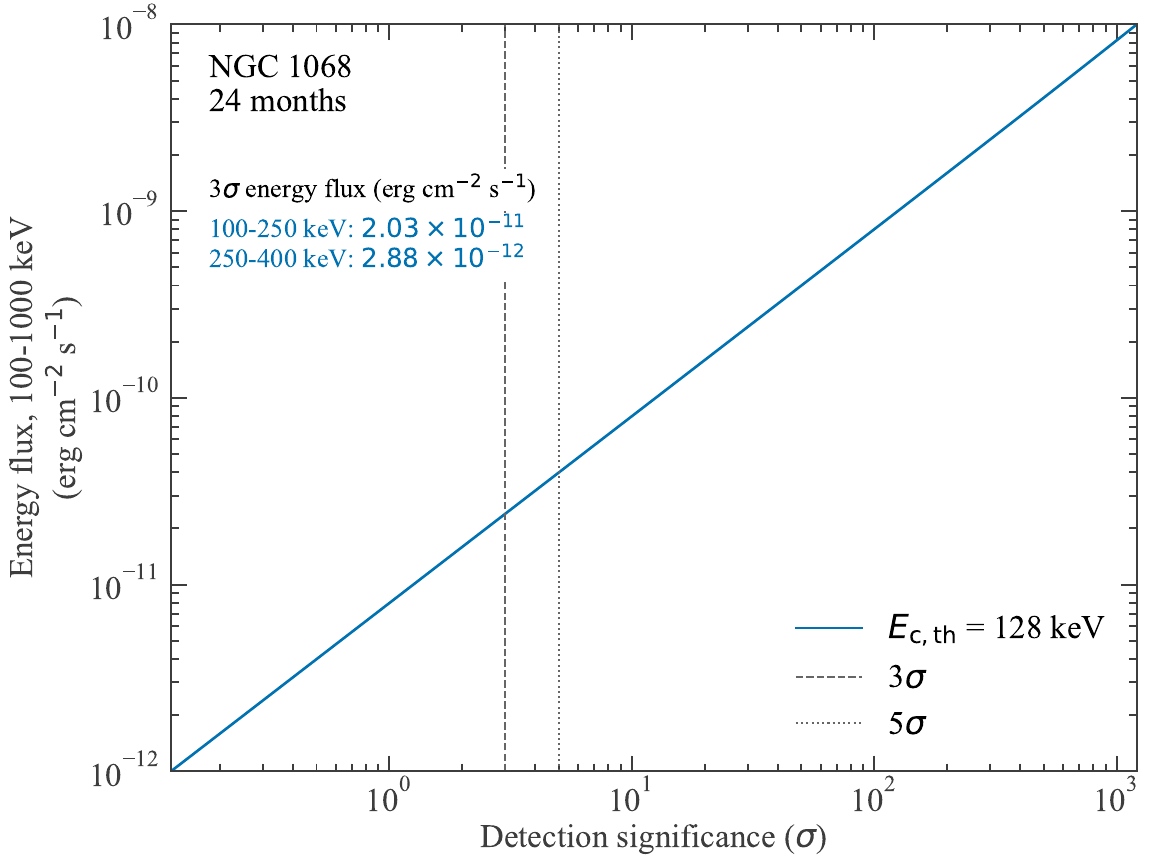

In [8]:
case_128 = calculate_cutoff_case(128.0)
fig_128, ax_128 = plot_cutoff_case(case_128)


## 8. Compare the two cutoff cases

Overlay the same 24-month results at 400 and 128 keV. Detection significance
remains on the x-axis and integrated energy flux on the y-axis. The cutoff
energies appear in the curve legend, and the annotation shows NGC 1068 and
24 months. The comparison uses the existing case results and saves one
additional PDF; it does not create an additional CSV.


Saved: /Users/parshadkp/Software/cosipy/docs/tutorials/source_injector/outputs/NGC1068_GTI_CPL_index_m2p1_Ec400_vs_Ec128_24months_band100_1000keV_Asimov_flux_significance.pdf


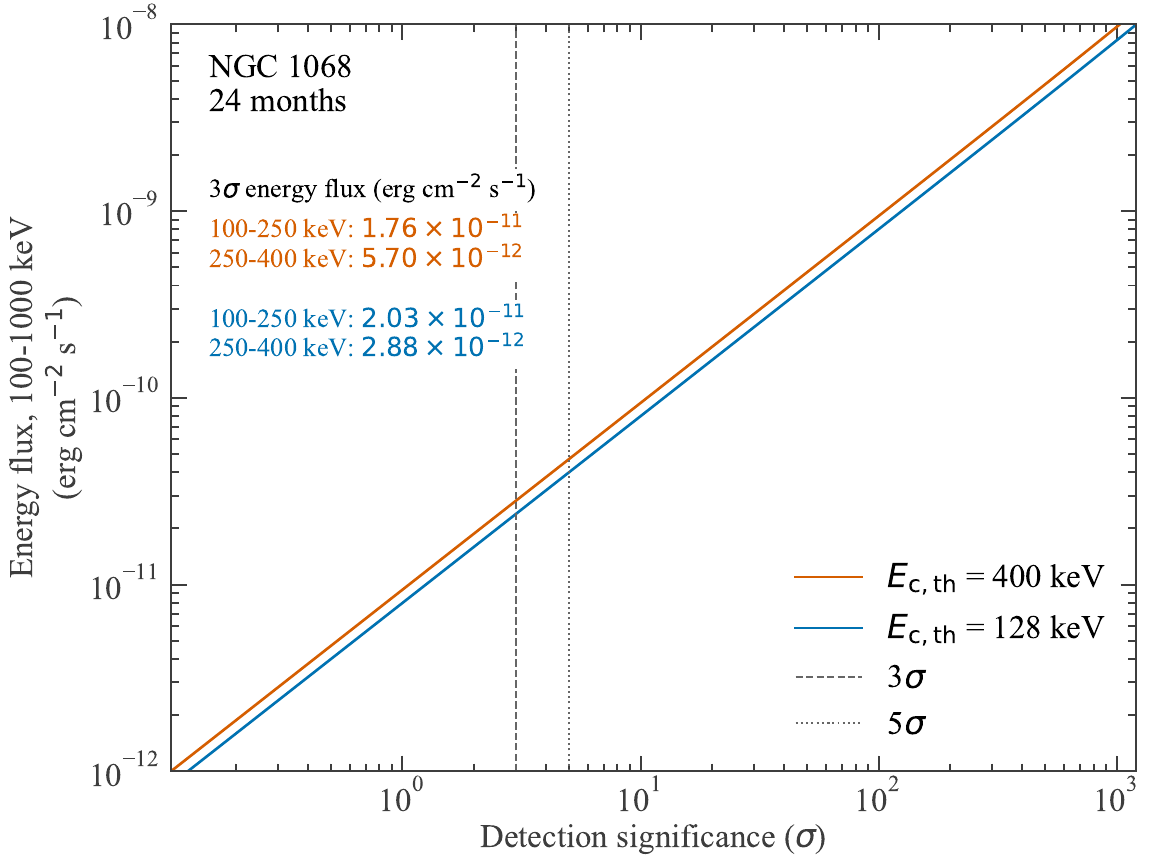

In [9]:
comparison_pdf_path = OUTPUT_ROOT / (
    f'NGC1068_GTI_CPL_index_{SPECTRAL_INDEX_TAG}_Ec400_vs_Ec128_{EXPOSURE_MONTHS:g}months_'
    f'{FLUX_BAND_TAG}_Asimov_flux_significance.pdf'
)
fig_comparison, ax_comparison = plot_cutoff_cases(
    [case_400, case_128], comparison_pdf_path,
)


## 9. Integrated photon flux

These additional figures use integrated photon flux over the same 100-1,000
keV band. For each fixed cutoff spectrum,

$$\Phi=\int_{100}^{1000}\frac{\mathrm{d}N}{\mathrm{d}E}\,\mathrm{d}E,
\qquad F_E=\int_{100}^{1000}E\frac{\mathrm{d}N}{\mathrm{d}E}\,\mathrm{d}E.$$

The conversion includes keV to erg. Each existing energy-flux point maps to a
photon-flux point for its spectrum, so the source expectation and TS are
unchanged. No new response convolution or Poisson ensemble is needed. The
photon-flux grid is spectrum dependent because the original grid was uniform
in log energy flux.

The photon-flux CSVs each contain 100 rows with only `photon_flux_ph_cm2_s` and
`ts`. The photon-flux figures retain detection significance on x and flux on y.
Their annotations show photon flux in 100-250 and 250-400 keV at the full-likelihood
3-sigma detection threshold. These are sub-band fluxes at that threshold,
not independent detection limits using only the sub-band events.


In [10]:
def add_photon_flux_output(case):
    """Convert the existing energy-flux grid and export photon flux with TS."""
    cutoff_keV = float(case['cutoff_keV'])

    def shape(energy_keV):
        return (energy_keV / PIVOT_KEV)**SPECTRAL_INDEX * np.exp(-energy_keV / cutoff_keV)

    photon_integral = quad(shape, *FLUX_BAND_KEV, epsabs=0.0, epsrel=1e-10)[0]
    energy_integral = quad(
        lambda energy: energy * shape(energy), *FLUX_BAND_KEV,
        epsabs=0.0, epsrel=1e-10,
    )[0] * u.keV.to(u.erg)
    photons_per_erg = photon_integral / energy_integral
    frame = case['results'].copy()
    frame['photon_flux_ph_cm2_s'] = frame['energy_flux_erg_cm2_s'] * photons_per_erg
    photon_csv_path = case['csv_path'].with_name(case['csv_path'].stem + '_photon_flux.csv')
    photon_pdf_path = case['pdf_path'].with_name(case['pdf_path'].stem + '_photon_flux.pdf')
    frame[['photon_flux_ph_cm2_s', 'ts']].to_csv(
        photon_csv_path, index=False, float_format='%.12g',
    )
    print('Saved:', photon_csv_path)
    return {
        **case, 'results': frame, 'photon_csv_path': photon_csv_path,
        'photon_pdf_path': photon_pdf_path, 'photons_per_erg': photons_per_erg,
    }


### Photon flux: 400 keV cutoff


Saved: /Users/parshadkp/Software/cosipy/docs/tutorials/source_injector/outputs/NGC1068_CPL400_Asimov/NGC1068_GTI_CPL_index_m2p1_Ec400_24months_band100_1000keV_Asimov_flux_significance_photon_flux.csv
Saved: /Users/parshadkp/Software/cosipy/docs/tutorials/source_injector/outputs/NGC1068_CPL400_Asimov/NGC1068_GTI_CPL_index_m2p1_Ec400_24months_band100_1000keV_Asimov_flux_significance_photon_flux.pdf


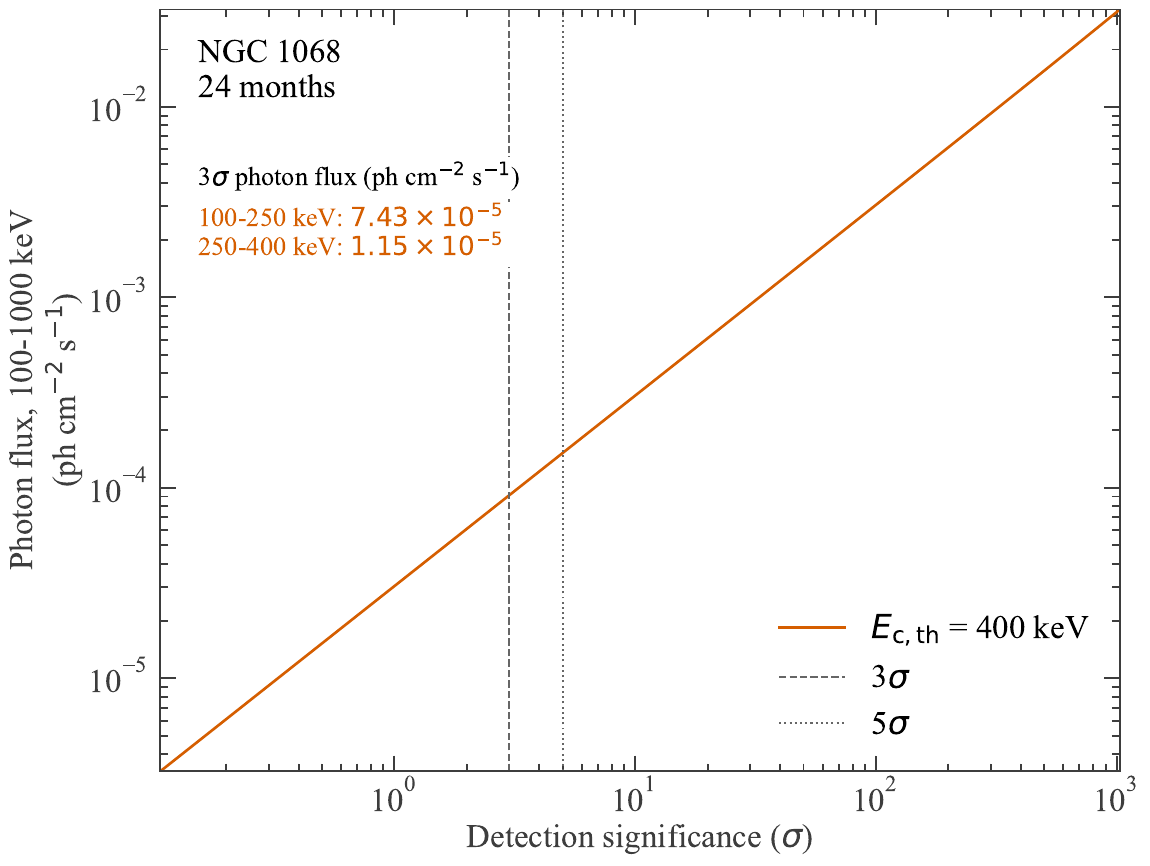

In [11]:
photon_case_400 = add_photon_flux_output(case_400)
fig_photon_400, ax_photon_400 = plot_cutoff_cases(
    [photon_case_400], photon_case_400['photon_pdf_path'], flux_kind='photon',
)


### Photon flux: 128 keV cutoff


Saved: /Users/parshadkp/Software/cosipy/docs/tutorials/source_injector/outputs/NGC1068_CPL128_Asimov/NGC1068_GTI_CPL_index_m2p1_Ec128_24months_band100_1000keV_Asimov_flux_significance_photon_flux.csv
Saved: /Users/parshadkp/Software/cosipy/docs/tutorials/source_injector/outputs/NGC1068_CPL128_Asimov/NGC1068_GTI_CPL_index_m2p1_Ec128_24months_band100_1000keV_Asimov_flux_significance_photon_flux.pdf


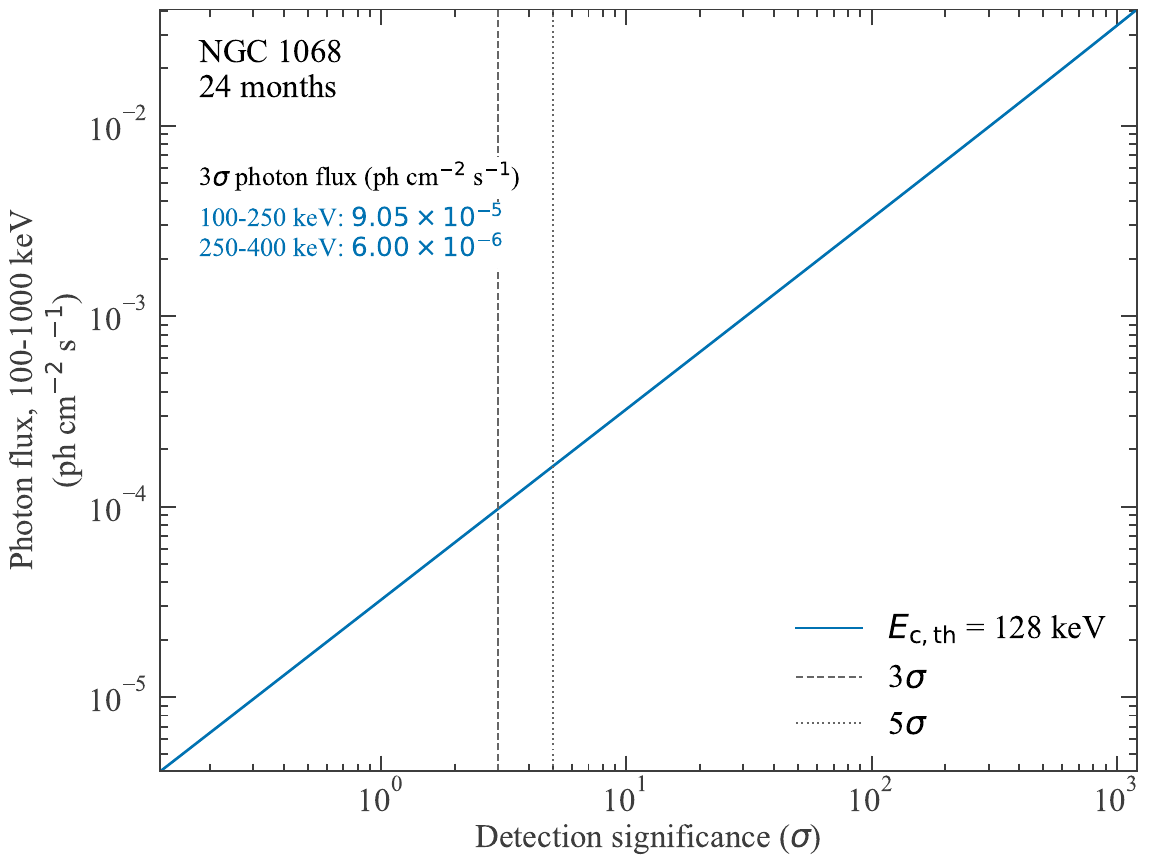

In [12]:
photon_case_128 = add_photon_flux_output(case_128)
fig_photon_128, ax_photon_128 = plot_cutoff_cases(
    [photon_case_128], photon_case_128['photon_pdf_path'], flux_kind='photon',
)


### Photon flux: cutoff comparison


Saved: /Users/parshadkp/Software/cosipy/docs/tutorials/source_injector/outputs/NGC1068_GTI_CPL_index_m2p1_Ec400_vs_Ec128_24months_band100_1000keV_Asimov_flux_significance_photon_flux.pdf


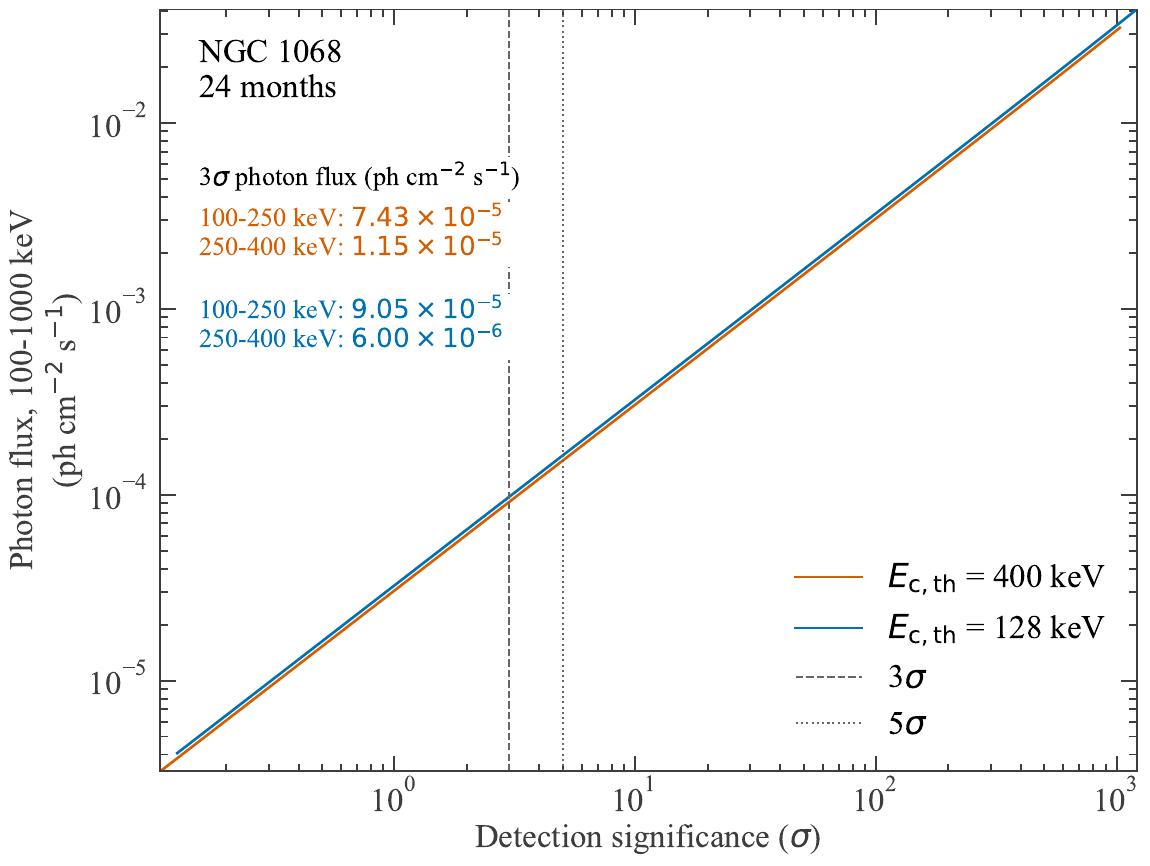

In [13]:
photon_comparison_pdf_path = comparison_pdf_path.with_name(
    comparison_pdf_path.stem + '_photon_flux.pdf'
)
fig_photon_comparison, ax_photon_comparison = plot_cutoff_cases(
    [photon_case_400, photon_case_128], photon_comparison_pdf_path,
    flux_kind='photon',
)


## Later: Poisson realizations

`case_400` and `case_128` each retain the response-folded source template,
background template, support mask, and reference normalization. For each trial
flux, draw Poisson source-plus-background counts and fit a nonnegative source
amplitude with the same background-normalization policy before evaluating the
exact zero-source null. The Asimov shortcut above applies to expectation data.
No Poisson realizations are run in this notebook.
